# Projeto 1 - Priorização de ajuda humanitária
Pipeline de mineração de dados: limpeza, escolha dos indicadores, tratamento de
faltantes, outliers e assimetria, escalonamento, K-Means, agrupamento hierárquico,
testes de robustez e recomendação por perfil.

Para rodar: deixe `paises_help_international.csv` na mesma pasta do notebook e execute
todas as células. As figuras vão para `figuras/` e as tabelas para `saidas/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import cophenet, dendrogram, fcluster, linkage, to_tree
from scipy.spatial.distance import cdist, pdist
from scipy.stats import skew
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, KNNImputer
from sklearn.metrics import adjusted_rand_score, silhouette_samples, silhouette_score
from sklearn.preprocessing import PowerTransformer, StandardScaler

ARQUIVO = "paises_help_international.csv"
SEMENTE = 42
K_FINAL = 6
INDICADORES = ["child_mort", "income", "inflation", "health"]

Path("figuras").mkdir(exist_ok=True)
Path("saidas").mkdir(exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# cores usadas nos gráficos (cinza para o que é contexto, azul para o destaque)
AZUL, LARANJA, VERDE_AGUA = "#2a78d6", "#eb6834", "#1baf7a"
CINZA, CINZA_CLARO, TINTA = "#898781", "#c3c2b7", "#0b0b0b"

plt.rcParams.update({
    "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": CINZA_CLARO, "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "figure.dpi": 150,
})

## 1. Carregamento e auditoria de qualidade
Dois tipos de problema aparecem na base: o código 99999 usado como "sem dado" e
valores fisicamente impossíveis (percentual acima de 100, expectativa de vida de
205 anos, mortalidade negativa etc.). Os dois viram NaN e são imputados depois.

In [2]:
bruto = pd.read_csv(ARQUIVO).set_index("country")
numericas = bruto.columns.tolist()
print(bruto.shape)
print("Faltantes originais:", int(bruto.isna().sum().sum()))

# faixa plausível de cada variável (unidade original do dicionário de dados)
FAIXAS = {
    "child_mort": (0, 300), "exports": (0, 300), "imports": (0, 300),
    "health": (0, 30), "income": (0, 200_000), "gdpp": (0, 200_000),
    "inflation": (-50, 1000), "life_expec": (20, 90), "total_fer": (0.5, 10),
    "medicos_por_1000": (0, 10), "cesta_basica_salario_pct": (0, 500),
}
for c in numericas:
    if c.endswith("_pct") and c != "cesta_basica_salario_pct":
        FAIXAS[c] = (0, 100)

registro = []
dados = bruto.copy()
for c in numericas:
    lo, hi = FAIXAS[c]
    for pais, v in bruto[c].items():
        if pd.isna(v):
            continue
        if v == 99999:
            motivo = "código 99999 (sem dado)"
        elif v < lo or v > hi:
            motivo = f"fora da faixa plausível [{lo}, {hi}]"
        else:
            continue
        registro.append({"pais": pais, "variavel": c, "valor": v, "problema": motivo})
        dados.loc[pais, c] = np.nan

registro = pd.DataFrame(registro).sort_values(["problema", "variavel"])
registro.to_csv("saidas/registro_correcoes.csv", index=False)
print(registro.to_string(index=False))
print("Valores invalidados:", len(registro))
print("Faltantes após a auditoria:", int(dados.isna().sum().sum()))
print("Faltantes nos 4 indicadores:\n", dados[INDICADORES].isna().sum())

(167, 17)
Faltantes originais: 15
      pais                 variavel    valor                            problema
    Angola       acesso_energia_pct  99999.0             código 99999 (sem dado)
     Nepal        acesso_esgoto_pct  99999.0             código 99999 (sem dado)
    Zambia        alfabetizacao_pct  99999.0             código 99999 (sem dado)
     Ghana cesta_basica_salario_pct  99999.0             código 99999 (sem dado)
    Uganda                     gdpp  99999.0             código 99999 (sem dado)
 Guatemala                   health  99999.0             código 99999 (sem dado)
   Morocco                  imports  99999.0             código 99999 (sem dado)
Bangladesh                   income  99999.0             código 99999 (sem dado)
  Pakistan             internet_pct  99999.0             código 99999 (sem dado)
   Bolivia         medicos_por_1000  99999.0             código 99999 (sem dado)
    Turkey                inflation 100000.0 fora da faixa plausível [-50, 

## 2. Correlação entre as variáveis e escolha dos 4 indicadores
Usamos Spearman porque várias variáveis são muito assimétricas e Spearman trabalha
com postos, então não é puxado por extremos. Critério de redundância: |rho| > 0,9.

A escolha segue uma lógica de **dois indicadores de necessidade** e **dois que orientam
o tipo de ajuda**:

| Indicador | Papel | Por que entra |
|---|---|---|
| `child_mort` | necessidade | Resume o bloco de desenvolvimento: tem \|rho\| entre 0,87 e 0,95 com as outras 11 variáveis desse bloco (expectativa de vida, água, esgoto, pobreza extrema, cesta básica, médicos...). Usar mais de uma delas só repetiria a mesma informação. |
| `income` | necessidade e capacidade de resposta | Mede quanto o próprio país consegue bancar. Com rho = −0,87 fica abaixo do corte e separa países com mortalidade parecida e recursos muito diferentes. Fica no lugar do PIB per capita (rho = 0,98 com a renda). |
| `health` | estratégia | Diz se o problema é falta de dinheiro na saúde (gasto baixo) ou capacidade de transformar em resultado o que já se gasta (gasto alto). Muda o tipo de intervenção. |
| `inflation` | estratégia | Inflação alta corrói ajuda em dinheiro e sinaliza instabilidade. Muda a forma da ajuda (bens e serviços em vez de transferências). |

Exportações e importações também são pouco correlacionadas com o resto, mas medem
abertura comercial, que não informa nem a necessidade nem a forma da ajuda. A seção 9
testa o efeito de trocar cada indicador.

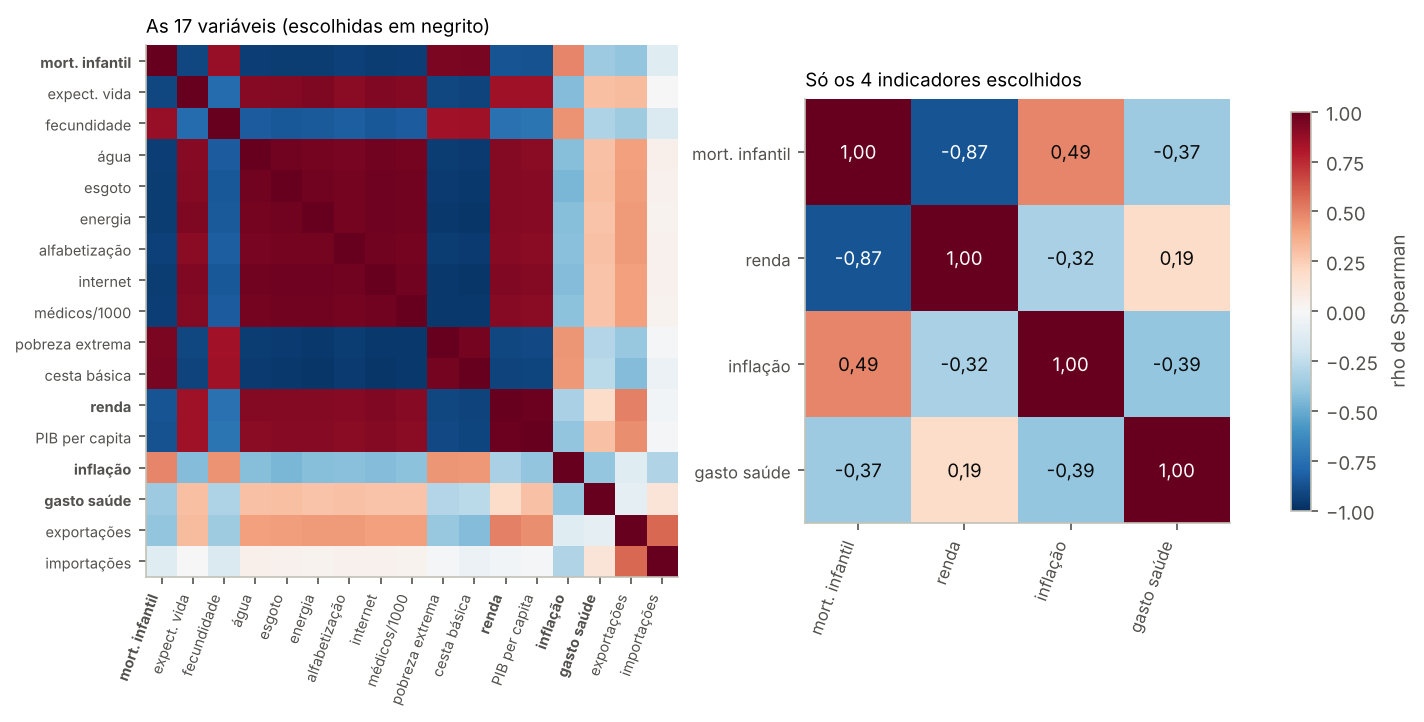

            child_mort  income  inflation  health
child_mort        1.00   -0.87       0.49   -0.37
income           -0.87    1.00      -0.32    0.19
inflation         0.49   -0.32       1.00   -0.39
health           -0.37    0.19      -0.39    1.00
Correlação do bloco 'desenvolvimento' com mortalidade infantil e renda:
                          child_mort  income
life_expec                     -0.91    0.84
total_fer                       0.87   -0.74
gdpp                           -0.87    0.98
acesso_agua_pct                -0.94    0.92
acesso_esgoto_pct              -0.95    0.92
acesso_energia_pct             -0.95    0.92
alfabetizacao_pct              -0.94    0.91
internet_pct                   -0.95    0.92
medicos_por_1000               -0.94    0.91
extrema_pobreza_pct             0.94   -0.91
cesta_basica_salario_pct        0.95   -0.93


In [3]:
corr = dados.corr(method="spearman")
corr.round(2).to_csv("saidas/correlacao_spearman.csv")

nomes_curtos = {
    "child_mort": "mort. infantil", "exports": "exportações", "health": "gasto saúde",
    "imports": "importações", "income": "renda", "inflation": "inflação",
    "life_expec": "expect. vida", "total_fer": "fecundidade", "gdpp": "PIB per capita",
    "acesso_agua_pct": "água", "acesso_esgoto_pct": "esgoto", "acesso_energia_pct": "energia",
    "alfabetizacao_pct": "alfabetização", "internet_pct": "internet",
    "medicos_por_1000": "médicos/1000", "extrema_pobreza_pct": "pobreza extrema",
    "cesta_basica_salario_pct": "cesta básica",
}
ordem = ["child_mort", "life_expec", "total_fer", "acesso_agua_pct", "acesso_esgoto_pct",
         "acesso_energia_pct", "alfabetizacao_pct", "internet_pct", "medicos_por_1000",
         "extrema_pobreza_pct", "cesta_basica_salario_pct", "income", "gdpp",
         "inflation", "health", "exports", "imports"]
cm = corr.loc[ordem, ordem]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(9.5, 4.7), gridspec_kw={"width_ratios": [1.6, 1]},
                        layout="constrained")
im = ax.imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(ordem)), [nomes_curtos[c] for c in ordem], rotation=70, ha="right", fontsize=7)
ax.set_yticks(range(len(ordem)), [nomes_curtos[c] for c in ordem], fontsize=7)
for c in INDICADORES:  # marca os indicadores escolhidos
    k = ordem.index(c)
    ax.get_yticklabels()[k].set_fontweight("bold")
    ax.get_xticklabels()[k].set_fontweight("bold")
ax.set_title("As 17 variáveis (escolhidas em negrito)", fontsize=9, loc="left")
# painel da direita: só os 4 escolhidos, com os valores
c4 = corr.loc[INDICADORES, INDICADORES]
ax2.imshow(c4, cmap="RdBu_r", vmin=-1, vmax=1)
rot4 = [nomes_curtos[c] for c in INDICADORES]
ax2.set_xticks(range(4), rot4, rotation=70, ha="right", fontsize=8)
ax2.set_yticks(range(4), rot4, fontsize=8)
for i in range(4):
    for j in range(4):
        v = c4.iat[i, j]
        ax2.text(j, i, f"{v:.2f}".replace(".", ","), ha="center", va="center", fontsize=9,
                 color="white" if abs(v) > 0.6 else TINTA)
ax2.set_title("Só os 4 indicadores escolhidos", fontsize=9, loc="left")
fig.colorbar(im, ax=[ax, ax2], shrink=0.75, label="rho de Spearman")
fig.savefig("figuras/fig1_correlacao.png", bbox_inches="tight")
plt.show()

print(corr.loc[INDICADORES, INDICADORES].round(2))
bloco = ["life_expec", "total_fer", "gdpp", "acesso_agua_pct", "acesso_esgoto_pct",
         "acesso_energia_pct", "alfabetizacao_pct", "internet_pct", "medicos_por_1000",
         "extrema_pobreza_pct", "cesta_basica_salario_pct"]
print("Correlação do bloco 'desenvolvimento' com mortalidade infantil e renda:")
print(corr.loc[bloco, ["child_mort", "income"]].round(2))

## 3. Outliers e assimetria
Regra aplicada a todas as variáveis (só com os valores observados):
1. se a variável é estritamente positiva e |assimetria| > 1, aplica log natural;
2. o que ainda ficar fora das cercas de Tukey (Q1 - 1,5 IQR, Q3 + 1,5 IQR) é
   winsorizado na cerca, sem excluir o país.

A winsorização só afeta a matriz usada no agrupamento. As tabelas de perfil e o resultado
final usam os valores observados, então a Nigéria continua aparecendo com inflação de 104%.

In [4]:
def cercas(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


tratado = dados.copy()
resumo_trat = []
usa_log = {}
for c in numericas:
    s = dados[c].dropna()
    lo0, hi0 = cercas(s)
    n_out_bruto = int(((s < lo0) | (s > hi0)).sum())
    usa_log[c] = bool((s > 0).all() and abs(skew(s)) > 1)
    t = np.log(dados[c]) if usa_log[c] else dados[c].copy()
    lo, hi = cercas(t.dropna())
    fora = t[(t < lo) | (t > hi)].dropna()
    tratado[c] = t.clip(lo, hi)
    resumo_trat.append({
        "variavel": c, "assimetria_bruta": skew(s), "outliers_brutos": n_out_bruto,
        "log": usa_log[c], "winsorizados": len(fora),
        "paises_winsorizados": ", ".join(fora.index),
        "assimetria_final": skew(tratado[c].dropna()),
    })
resumo_trat = pd.DataFrame(resumo_trat).set_index("variavel")
resumo_trat.round(2).to_csv("saidas/tratamento_outliers_assimetria.csv")
print(resumo_trat.loc[INDICADORES].round(2).to_string())

for c in INDICADORES:
    s = dados[c].dropna()
    lo, hi = cercas(s)
    print(c, "outliers na escala original:", s[(s < lo) | (s > hi)].sort_values().to_dict())

# alternativa testada e descartada para a inflação: Yeo-Johnson (aceita negativos),
# mas estica a cauda da esquerda e transforma deflação leve em outlier
infl_obs = dados["inflation"].dropna()
yj = pd.Series(PowerTransformer(method="yeo-johnson").fit_transform(infl_obs.to_frame()).ravel(),
               index=infl_obs.index)
print("Inflação com Yeo-Johnson, países a mais de 3 desvios:", yj[yj.abs() > 3].round(2).to_dict())

            assimetria_bruta  outliers_brutos    log  winsorizados                                           paises_winsorizados  assimetria_final
variavel                                                                                                                                          
child_mort              1.45                4   True             0                                                                           -0.02
income                  2.21                8   True             0                                                                           -0.25
inflation               5.27                5  False             5  Equatorial Guinea, Mongolia, Nigeria, Timor-Leste, Venezuela              0.97
health                  0.70                1  False             1                                                 United States              0.49
child_mort outliers na escala original: {'Central African Republic': 149.0, 'Chad': 150.0, 'Sierra Leone': 165.0, 'Hai

## 4. Valores faltantes
Nos 4 indicadores há 7 buracos: 2 que já vieram vazios e 5 criados pela auditoria.
Duas candidatas, ambas no espaço tratado (log + winsorização) e padronizado, usando as
17 variáveis:

- **KNN**: média dos k países mais parecidos;
- **MICE** (imputação iterativa): regressão de cada variável nas outras, repetida até estabilizar.

As variáveis do bloco de desenvolvimento são redundantes para o agrupamento, mas
justamente por isso ajudam a achar países parecidos na hora de imputar. O método é
escolhido **por indicador**, com base na validação abaixo.

In [5]:
def imputar_knn(df_tratado, k=5):
    media, desvio = df_tratado.mean(), df_tratado.std()
    z = (df_tratado - media) / desvio
    zi = KNNImputer(n_neighbors=k).fit_transform(z)
    return pd.DataFrame(zi, index=z.index, columns=z.columns) * desvio + media


def imputar_mice(df_tratado):
    """Imputação iterativa: regressão de cada variável nas outras."""
    media, desvio = df_tratado.mean(), df_tratado.std()
    z = (df_tratado - media) / desvio
    zi = IterativeImputer(max_iter=20, random_state=SEMENTE).fit_transform(z)
    return pd.DataFrame(zi, index=z.index, columns=z.columns) * desvio + media


def para_escala_original(df_tratado):
    out = df_tratado.copy()
    for c in out:
        if usa_log[c]:
            out[c] = np.exp(out[c])
    return out


def preparar(df_dados):
    """Repete o tratamento (log + winsorização) com as cercas calculadas no df recebido."""
    t = df_dados.copy()
    for c in numericas:
        x = np.log(df_dados[c]) if usa_log[c] else df_dados[c]
        lo, hi = cercas(x.dropna())
        t[c] = x.clip(lo, hi)
    return t

### Validação da imputação
Escondemos 15 valores conhecidos de cada indicador, imputamos por KNN (k = 3, 5, 10),
MICE, mediana e média, e comparamos com o valor verdadeiro. Repetimos 100 vezes.
Em cada indicador fica o método, entre KNN k = 5 e MICE, com o menor erro.

In [6]:
rng = np.random.default_rng(SEMENTE)
erros = {m: {c: [] for c in INDICADORES}
         for m in ["KNN k=3", "KNN k=5", "KNN k=10", "MICE", "mediana", "média"]}
for _ in range(100):
    mascarado = dados.copy()
    escondidos = {}
    for c in INDICADORES:
        conhecidos = dados.index[dados[c].notna()]
        escondidos[c] = rng.choice(conhecidos, 15, replace=False)
        mascarado.loc[escondidos[c], c] = np.nan
    t = preparar(mascarado)
    for k in (3, 5, 10):
        est = para_escala_original(imputar_knn(t, k))
        for c in INDICADORES:
            erros[f"KNN k={k}"][c].append(np.median(np.abs(est.loc[escondidos[c], c] - dados.loc[escondidos[c], c])))
    est = para_escala_original(imputar_mice(t))
    for c in INDICADORES:
        erros["MICE"][c].append(np.median(np.abs(est.loc[escondidos[c], c] - dados.loc[escondidos[c], c])))
    for c in INDICADORES:
        verdade = dados.loc[escondidos[c], c]
        erros["mediana"][c].append(np.median(np.abs(mascarado[c].median() - verdade)))
        erros["média"][c].append(np.median(np.abs(mascarado[c].mean() - verdade)))

validacao = pd.DataFrame({m: {c: np.mean(v) for c, v in e.items()} for m, e in erros.items()})
validacao.round(2).to_csv("saidas/validacao_imputacao.csv")
print("Erro absoluto mediano (média de 100 repetições), na unidade original:")
print(validacao.round(2))

METODO = validacao[["KNN k=5", "MICE"]].idxmin(axis=1)
print("\nMétodo escolhido por indicador:")
print(METODO.to_string())

Erro absoluto mediano (média de 100 repetições), na unidade original:
            KNN k=3  KNN k=5  KNN k=10     MICE  mediana     média
child_mort     4.43     4.48      4.47     4.61    15.69     27.84
income      1839.70  1779.27   1782.60  1075.83  7699.68  12336.71
inflation      3.42     3.45      3.41     3.80     4.15      5.72
health         1.34     1.34      1.40     1.45     1.89      1.97

Método escolhido por indicador:
child_mort    KNN k=5
income           MICE
inflation     KNN k=5
health        KNN k=5


### Imputação final e checagem de coerência
Cada indicador recebe o método escolhido. Nas outras 13 variáveis, que só aparecem na
descrição dos grupos, fica o KNN. Depois conferimos o valor imputado contra uma variável
muito correlacionada que foi observada: a renda anda junto com o PIB per capita
(rho = 0,98), então a razão renda / PIB per capita do país imputado deve ficar na faixa
dos outros países.

In [7]:
imp_knn = imputar_knn(tratado, k=5)
imp_mice = imputar_mice(tratado)
imputado_t = imp_knn.copy()
for c in INDICADORES:
    if METODO[c] == "MICE":
        imputado_t[c] = imp_mice[c]
imputado_orig = para_escala_original(imputado_t)
# para descrever os países usamos o valor observado sempre que ele existe;
# o valor imputado só entra onde havia buraco (assim a winsorização não aparece nos perfis)
completo = dados.fillna(imputado_orig)
completo.to_csv("saidas/base_limpa_imputada.csv")

faltavam = dados[INDICADORES].isna()
knn_orig, mice_orig = para_escala_original(imp_knn), para_escala_original(imp_mice)
tab_imp = []
for c in INDICADORES:
    for pais in dados.index[faltavam[c]]:
        tab_imp.append({"pais": pais, "variavel": c, "valor_bruto": bruto.loc[pais, c],
                        "knn": knn_orig.loc[pais, c], "mice": mice_orig.loc[pais, c],
                        "usado": completo.loc[pais, c], "mediana": dados[c].median()})
tab_imp = pd.DataFrame(tab_imp)
tab_imp.round(2).to_csv("saidas/valores_imputados.csv", index=False)
print(tab_imp.round(2).to_string(index=False))

razao = (dados["income"] / dados["gdpp"]).dropna()
print(f"\nRenda / PIB per capita nos países com os dois observados: "
      f"mediana {razao.median():.2f}, máximo {razao.max():.2f}")
for pais in dados.index[faltavam["income"]]:
    print(f"{pais}: com KNN a razão seria {knn_orig.loc[pais, 'income'] / dados.loc[pais, 'gdpp']:.1f}; "
          f"com MICE é {mice_orig.loc[pais, 'income'] / dados.loc[pais, 'gdpp']:.1f}")

      pais   variavel  valor_bruto     knn    mice   usado  mediana
     Chile child_mort         -8.0   10.55   10.25   10.55    19.30
  Tanzania child_mort          NaN   94.09   88.32   94.09    19.30
Bangladesh     income      99999.0 6726.83 3303.12 3303.12 10180.00
    Jordan  inflation          NaN    2.93    6.24    2.93     5.14
    Turkey  inflation     100000.0    9.48    7.50    9.48     5.14
 Guatemala     health      99999.0    4.91    6.16    4.91     6.22
    Poland     health        999.0    8.14    7.86    8.14     6.22

Renda / PIB per capita nos países com os dois observados: mediana 2.01, máximo 4.12
Bangladesh: com KNN a razão seria 8.9; com MICE é 4.4


## 5. Matriz final, escalonamento e métrica de distância
Só os 4 indicadores entram no agrupamento. Padronizamos com z-score para que cada um
pese o mesmo na distância: sem isso, a renda (em dólares) responderia por praticamente
toda a variância, como mostra a saída abaixo.

**Métrica: distância euclidiana.** Motivos:

1. O K-Means e o Ward minimizam a soma dos quadrados das distâncias euclidianas aos
   centros dos grupos. Usar outra métrica com esses algoritmos quebraria a lógica deles.
2. A vantagem usual da Manhattan é sofrer menos com valores extremos, e o log e a
   winsorização já tiraram os extremos (máximo de 2,8 desvios na matriz final).
3. É fácil de explicar: dois países são parecidos quando estão perto nos quatro
   indicadores ao mesmo tempo, cada um medido em desvios-padrão.

Um efeito a ter em mente: mortalidade infantil e renda têm rho = −0,87, então o eixo de
necessidade conta quase duas vezes na distância. Aqui isso é desejado: para uma ONG
humanitária a necessidade deve pesar mais que o tipo de ajuda. A distância de Mahalanobis
anularia esse peso extra; ela e a Manhattan são testadas na seção 9. A distância de
correlação (ou cosseno) foi descartada porque compara só o formato do perfil e ignora o
nível: um país com todos os indicadores um pouco ruins ficaria igual a um com todos
muito ruins.

In [8]:
X = imputado_t[INDICADORES].copy()
print("Variância de cada indicador antes de padronizar (escala tratada):")
print((X.var() / X.var().sum() * 100).round(1).rename("% da variância total"))
print("Na escala original (sem log nem padronização):")
print((completo[INDICADORES].var() / completo[INDICADORES].var().sum() * 100).round(3))

Xs = pd.DataFrame(StandardScaler().fit_transform(X), index=X.index, columns=INDICADORES)
Xs.to_csv("saidas/matriz_padronizada.csv")
print(Xs.describe().round(2))

Variância de cada indicador antes de padronizar (escala tratada):
child_mort     2.4
income         2.7
inflation     82.0
health        12.9
Name: % da variância total, dtype: float64
Na escala original (sem log nem padronização):
child_mort      0.0
income        100.0
inflation       0.0
health          0.0
dtype: float64
       child_mort  income  inflation  health
count      167.00  167.00     167.00  167.00
mean         0.00    0.00       0.00    0.00
std          1.00    1.00       1.00    1.00
min         -1.81   -2.21      -1.68   -1.86
25%         -0.81   -0.82      -0.78   -0.70
50%         -0.08    0.07      -0.29   -0.21
75%          0.93    0.75       0.55    0.68
max          1.97    2.14       2.61    2.80


### Figura de antes e depois do tratamento

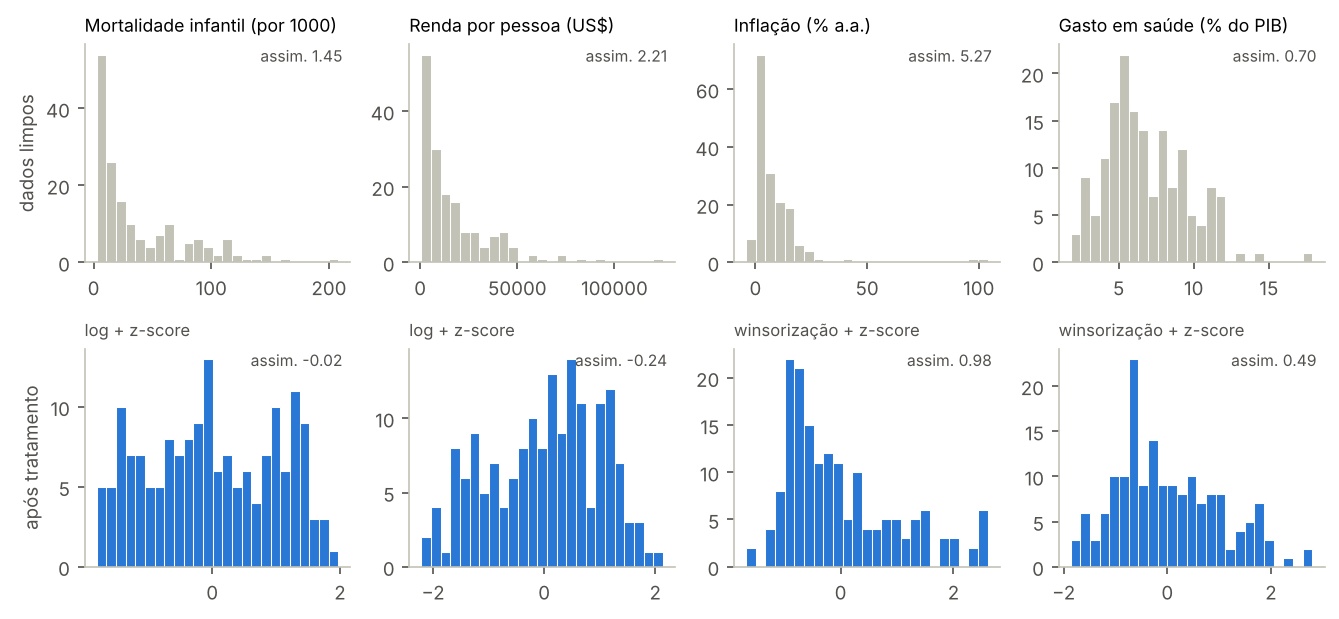

In [9]:
rotulos = {"child_mort": "Mortalidade infantil (por 1000)", "income": "Renda por pessoa (US$)",
           "inflation": "Inflação (% a.a.)", "health": "Gasto em saúde (% do PIB)"}
fig, axes = plt.subplots(2, 4, figsize=(9, 4.2))
for j, c in enumerate(INDICADORES):
    s0 = dados[c].dropna()
    axes[0, j].hist(s0, bins=25, color=CINZA_CLARO, edgecolor="white", linewidth=0.5)
    axes[0, j].set_title(rotulos[c], fontsize=8.5, loc="left")
    axes[0, j].text(0.97, 0.92, f"assim. {skew(s0):.2f}", transform=axes[0, j].transAxes,
                    ha="right", fontsize=7.5, color="#52514e")
    s1 = Xs[c]
    axes[1, j].hist(s1, bins=25, color=AZUL, edgecolor="white", linewidth=0.5)
    nome = "log + z-score" if usa_log[c] else "winsorização + z-score"
    axes[1, j].set_title(nome, fontsize=8, loc="left", color="#52514e")
    axes[1, j].text(0.97, 0.92, f"assim. {skew(s1):.2f}", transform=axes[1, j].transAxes,
                    ha="right", fontsize=7.5, color="#52514e")
axes[0, 0].set_ylabel("dados limpos")
axes[1, 0].set_ylabel("após tratamento")
fig.tight_layout()
fig.savefig("figuras/fig2_distribuicoes.png", bbox_inches="tight")
plt.show()

## 6. K-Means: escolha de k pelo cotovelo e pela silhueta

    inercia  silhueta  queda_inercia_%
k                                     
2   403.142     0.342              NaN
3   305.085     0.346           24.323
4   241.896     0.318           20.712
5   199.920     0.328           17.353
6   170.229     0.336           14.851
7   151.430     0.297           11.043
8   137.661     0.304            9.093
9   125.111     0.303            9.116
10  115.932     0.289            7.337


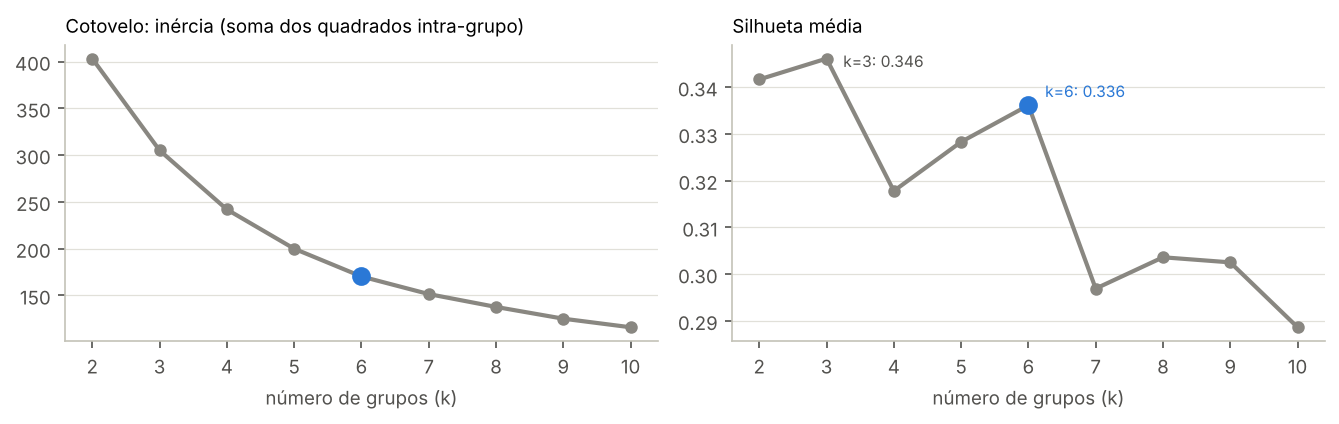

In [10]:
def melhor_kmeans(k, rodadas=100, matriz=None):
    """K-Means cai em mínimos locais; rodamos 100 sementes (10 inicializações cada)
    e ficamos com a solução de menor inércia. Por padrão usa a matriz final Xs."""
    matriz = Xs if matriz is None else matriz
    melhor = None
    for s in range(rodadas):
        km = KMeans(n_clusters=k, n_init=10, random_state=s).fit(matriz)
        if melhor is None or km.inertia_ < melhor.inertia_:
            melhor = km
    return melhor


metricas = []
for k in range(2, 11):
    km = melhor_kmeans(k)
    metricas.append({"k": k, "inercia": km.inertia_, "silhueta": silhouette_score(Xs, km.labels_)})
metricas = pd.DataFrame(metricas).set_index("k")
metricas["queda_inercia_%"] = -metricas["inercia"].pct_change() * 100
metricas.round(3).to_csv("saidas/metricas_k.csv")
print(metricas.round(3))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 2.9))
ks = metricas.index
a1.plot(ks, metricas["inercia"], color=CINZA, lw=2, marker="o", ms=5)
a1.plot([K_FINAL], [metricas.loc[K_FINAL, "inercia"]], marker="o", ms=8, color=AZUL)
a1.set_title("Cotovelo: inércia (soma dos quadrados intra-grupo)", fontsize=9, loc="left")
a1.set_xlabel("número de grupos (k)")
a1.grid(axis="y", color="#e1e0d9", lw=0.6)
a2.plot(ks, metricas["silhueta"], color=CINZA, lw=2, marker="o", ms=5)
a2.plot([K_FINAL], [metricas.loc[K_FINAL, "silhueta"]], marker="o", ms=8, color=AZUL)
for k, desloc in ((3, (8, -4)), (K_FINAL, (8, 4))):
    a2.annotate(f"k={k}: {metricas.loc[k, 'silhueta']:.3f}", (k, metricas.loc[k, "silhueta"]),
                textcoords="offset points", xytext=desloc, fontsize=7.5,
                color=AZUL if k == K_FINAL else "#52514e")
a2.set_title("Silhueta média", fontsize=9, loc="left")
a2.set_xlabel("número de grupos (k)")
a2.grid(axis="y", color="#e1e0d9", lw=0.6)
for a in (a1, a2):
    a.set_xticks(list(ks))
fig.tight_layout()
fig.savefig("figuras/fig3_escolha_k.png", bbox_inches="tight")
plt.show()

### Por que k = 6 e não k = 3 (a maior silhueta)?
O cotovelo não tem uma dobra nítida: a queda da inércia diminui aos poucos a partir de
k = 3. A silhueta é a mais alta em k = 3 (0,346), mas a vantagem sobre k = 6 (0,336) é
pequena, e o teste abaixo mostra que ela é ruído: em 50 subamostras com 80% dos países,
as médias ficam praticamente iguais (0,344 e 0,343) e k = 3 só ganha em 60% das vezes.
Além disso, a silhueta de k = 6 varia metade do que varia a de k = 3 (desvio de 0,011
contra 0,022).

Com as métricas empatadas, o desempate é a utilidade para a decisão. Com k = 3, 4 ou 5 a
inflação junta no mesmo grupo países ricos do Golfo (Kuwait, Arábia Saudita, Emirados) e
países muito pobres como Iêmen, Sudão, Nigéria e Angola, que pedem estratégias opostas.
Só com k = 6 esses dois perfis se separam (grupos C e E da seção 7).

As silhuetas, todas entre 0,29 e 0,35, indicam estrutura fraca: os países formam mais um
contínuo do que grupos isolados. Por isso os grupos devem ser lidos como faixas de perfil,
e a seção 9 identifica os países de fronteira.

In [11]:
def composicao(k):
    lab = melhor_kmeans(k).labels_
    g = completo[INDICADORES].assign(grupo=lab).groupby("grupo")
    return lab, pd.concat([g.size().rename("n"), g.median().round(1)], axis=1)


ricos_e_pobres = ["Qatar", "Kuwait", "Saudi Arabia", "United Arab Emirates",
                  "Yemen", "Sudan", "Nigeria", "Angola"]
for k in (3, 4, 5):
    lab_k, comp = composicao(k)
    print(f"k={k}\n", comp)
    g_inf = comp["inflation"].idxmax()
    membros = Xs.index[lab_k == g_inf]
    print("  grupo de inflação mais alta contém:",
          ", ".join(m for m in membros if m in ricos_e_pobres), "\n")

# a vantagem de k = 3 na silhueta é real ou é ruído?
# reagrupa 50 subamostras com 80% dos países e compara a silhueta de cada k
rng_sil = np.random.default_rng(SEMENTE)
sil_sub = {k: [] for k in (3, 4, 5, 6)}
for r in range(50):
    idx = rng_sil.choice(len(Xs), int(0.8 * len(Xs)), replace=False)
    sub = Xs.iloc[idx]
    for k in sil_sub:
        sil_sub[k].append(silhouette_score(sub, KMeans(k, n_init=20, random_state=r).fit(sub).labels_))
sil_sub = pd.DataFrame(sil_sub)
print("Silhueta em 50 subamostras de 80% dos países:")
print(sil_sub.describe().loc[["mean", "std", "min", "max"]].round(3))
print("Fração das subamostras em que k=3 supera k=6:", round((sil_sub[3] > sil_sub[6]).mean(), 2))

k=3
         n  child_mort   income  inflation  health
grupo                                            
0      34        23.8  14150.0       16.6     4.7
1      70        57.4   2870.0        5.7     5.3
2      63         6.1  25200.0        1.6     8.4
  grupo de inflação mais alta contém: Angola, Kuwait, Nigeria, Qatar, Saudi Arabia, Sudan, United Arab Emirates, Yemen 



k=4
         n  child_mort   income  inflation  health
grupo                                            
0      43         4.5  32500.0        1.2     9.4
1      53        18.9   9930.0        4.4     6.0
2      42        89.8   1755.0        6.8     5.7
3      29        27.3  15400.0       16.7     4.5
  grupo de inflação mais alta contém: Angola, Kuwait, Nigeria, Saudi Arabia, Sudan, United Arab Emirates, Yemen 



k=5
         n  child_mort   income  inflation  health
grupo                                            
0      43         4.5  32500.0        1.2     9.4
1      14        72.3   1635.0        7.7    10.8
2      27        26.1  16000.0       16.7     4.4
3      49        18.9   9960.0        4.2     6.0
4      34        85.6   2040.0        7.1     5.2
  grupo de inflação mais alta contém: Angola, Kuwait, Nigeria, Saudi Arabia, Sudan, United Arab Emirates, Yemen 



Silhueta em 50 subamostras de 80% dos países:
          3      4      5      6
mean  0.344  0.322  0.332  0.343
std   0.022  0.014  0.013  0.011
min   0.288  0.304  0.303  0.316
max   0.374  0.365  0.360  0.368
Fração das subamostras em que k=3 supera k=6: 0.6


### Modelo final (k = 6) e estabilidade

In [12]:
km_final = melhor_kmeans(K_FINAL)
rotulo_km = pd.Series(km_final.labels_, index=Xs.index)
print("Inércia da solução final:", round(km_final.inertia_, 3))

# quanto as outras sementes discordam da melhor solução?
outras = [KMeans(K_FINAL, n_init=10, random_state=s).fit(Xs) for s in range(100)]
print("Inércia nas 100 sementes: de", round(min(o.inertia_ for o in outras), 3),
      "a", round(max(o.inertia_ for o in outras), 3))
print("ARI com a melhor solução: mínimo",
      round(min(adjusted_rand_score(rotulo_km, o.labels_) for o in outras), 3))

# bootstrap: treina em reamostras e compara a atribuição dos 167 países
rng_boot = np.random.default_rng(SEMENTE)
ari_boot = []
for b in range(100):
    idx = rng_boot.choice(len(Xs), len(Xs), replace=True)
    km_b = KMeans(K_FINAL, n_init=10, random_state=b).fit(Xs.iloc[idx])
    ari_boot.append(adjusted_rand_score(rotulo_km, km_b.predict(Xs)))
print(f"ARI bootstrap: média {np.mean(ari_boot):.3f}, mediana {np.median(ari_boot):.3f}")

# sensibilidade à imputação: e se tivéssemos usado só KNN ou só MICE nos 4 indicadores?
for nome, imp in (("só KNN", imp_knn), ("só MICE", imp_mice)):
    Xs_alt = pd.DataFrame(StandardScaler().fit_transform(imp[INDICADORES]),
                          index=Xs.index, columns=INDICADORES)
    lab_alt = melhor_kmeans(K_FINAL, matriz=Xs_alt).labels_
    print(f"ARI entre a imputação escolhida e {nome}:", round(adjusted_rand_score(rotulo_km, lab_alt), 3))

Inércia da solução final: 170.229


Inércia nas 100 sementes: de 170.229 a 171.679
ARI com a melhor solução: mínimo 0.845


ARI bootstrap: média 0.748, mediana 0.786


ARI entre a imputação escolhida e só KNN: 1.0


ARI entre a imputação escolhida e só MICE: 1.0


## 7. Nomeando os grupos a partir dos perfis
Os nomes saem das medianas na escala original. Para o nome não depender da
numeração aleatória do K-Means, a regra abaixo identifica cada grupo pelo perfil.
O nome descreve a mediana do grupo: um país isolado pode fugir dele (o Catar, por
exemplo, está no grupo E pela renda alta e pelo gasto em saúde muito baixo, não pela
inflação). As colunas suplementares não entram no agrupamento; servem para conferir
se os grupos fazem sentido em outras dimensões de necessidade.

In [13]:
perfil = completo[INDICADORES].assign(g=rotulo_km).groupby("g").median()
ordem_mort = perfil["child_mort"].sort_values()
nomes = {}
alta_necessidade = ordem_mort.index[-3:]          # os 3 grupos de maior mortalidade
baixa_necessidade = ordem_mort.index[:-3]
p_alta = perfil.loc[alta_necessidade]
g_infl_alta = p_alta["inflation"].idxmax()
g_saude_alta = p_alta.drop(g_infl_alta)["health"].idxmax()
g_saude_baixa = [g for g in alta_necessidade if g not in (g_infl_alta, g_saude_alta)][0]
nomes[g_saude_baixa] = "A. Alta necessidade, saúde subfinanciada"
nomes[g_saude_alta] = "B. Alta necessidade, gasto em saúde alto"
nomes[g_infl_alta] = "C. Alta necessidade, inflação alta"
p_baixa = perfil.loc[baixa_necessidade]
g_rico = p_baixa["income"].idxmax()
g_med_infl = p_baixa.drop(g_rico)["inflation"].idxmax()
g_med = [g for g in baixa_necessidade if g not in (g_rico, g_med_infl)][0]
nomes[g_med] = "D. Renda média, estável"
nomes[g_med_infl] = "E. Renda média-alta, inflação alta, pouco gasto em saúde"
nomes[g_rico] = "F. Desenvolvidos"

grupo = rotulo_km.map(nomes)
eh_prior = grupo.str[0].isin(["A", "B", "C"])   # grupos de alta necessidade
sil = pd.Series(silhouette_samples(Xs, rotulo_km), index=Xs.index)

suplementares = ["life_expec", "acesso_agua_pct", "extrema_pobreza_pct",
                 "cesta_basica_salario_pct", "medicos_por_1000"]
tab_perfil = completo[INDICADORES + suplementares].assign(grupo=grupo).groupby("grupo").median()
tab_perfil.insert(0, "n", grupo.value_counts())
tab_perfil["silhueta_media"] = sil.groupby(grupo).mean()
tab_perfil = tab_perfil.sort_index()
tab_perfil.round(2).to_csv("saidas/perfil_grupos.csv")
print(tab_perfil.round(1).to_string())

for g in sorted(grupo.unique()):
    print(f"\n{g} ({(grupo == g).sum()}):", ", ".join(sorted(grupo.index[grupo == g])))

print("\nPaíses com silhueta negativa (casos de fronteira):")
print(sil[sil < 0].round(3).to_dict())

                                                           n  child_mort   income  inflation  health  life_expec  acesso_agua_pct  extrema_pobreza_pct  cesta_basica_salario_pct  medicos_por_1000  silhueta_media
grupo                                                                                                                                                                                                             
A. Alta necessidade, saúde subfinanciada                  31        88.2   2090.0        6.4     5.1        61.8             57.4                 55.3                     112.6               0.8             0.3
B. Alta necessidade, gasto em saúde alto                  11        81.0   1540.0        5.5    11.3        60.7             53.5                 53.8                     114.3               1.1             0.3
C. Alta necessidade, inflação alta                        16        75.7   3805.0       20.2     5.2        64.2             58.2                 51.7      

## 8. Agrupamento hierárquico (Ward) e dendrograma
O hierárquico serve de segunda opinião, independente do K-Means. Usamos a ligação de
Ward porque ela junta, a cada passo, os dois grupos cuja fusão menos aumenta a soma dos
quadrados intra-grupo, que é o mesmo critério do K-Means; assim a comparação entre os
dois métodos é justa.

A correlação cofenética da Ward é mais baixa que a da average e a da complete, mas essa
medida avalia o quanto a árvore preserva as distâncias entre pares, não se a partição é
útil. A tabela de tamanhos mostra o problema das outras ligações quando cortadas em 6.

         cofenetica     tamanhos_com_6_grupos
ward          0.579  [36, 36, 30, 28, 24, 13]
complete      0.628   [63, 34, 31, 23, 11, 5]
average       0.664    [69, 54, 24, 11, 7, 2]
single        0.461      [162, 1, 1, 1, 1, 1]
Silhueta Ward k=6: 0.273
ARI K-Means x Ward: 0.511
Ward                                                 1   2   3   4   5   6
K-Means                                                                   
A. Alta necessidade, saúde subfinanciada             0   0  11   1   1  18
B. Alta necessidade, gasto em saúde alto             0   0   0   1   0  10
C. Alta necessidade, inflação alta                   0   0   0   1  15   0
D. Renda média, estável                              0   2  19  26   0   0
E. Renda média-alta, inflação alta, pouco gasto...   0  10   0   1   8   0
F. Desenvolvidos                                    36   1   0   6   0   0


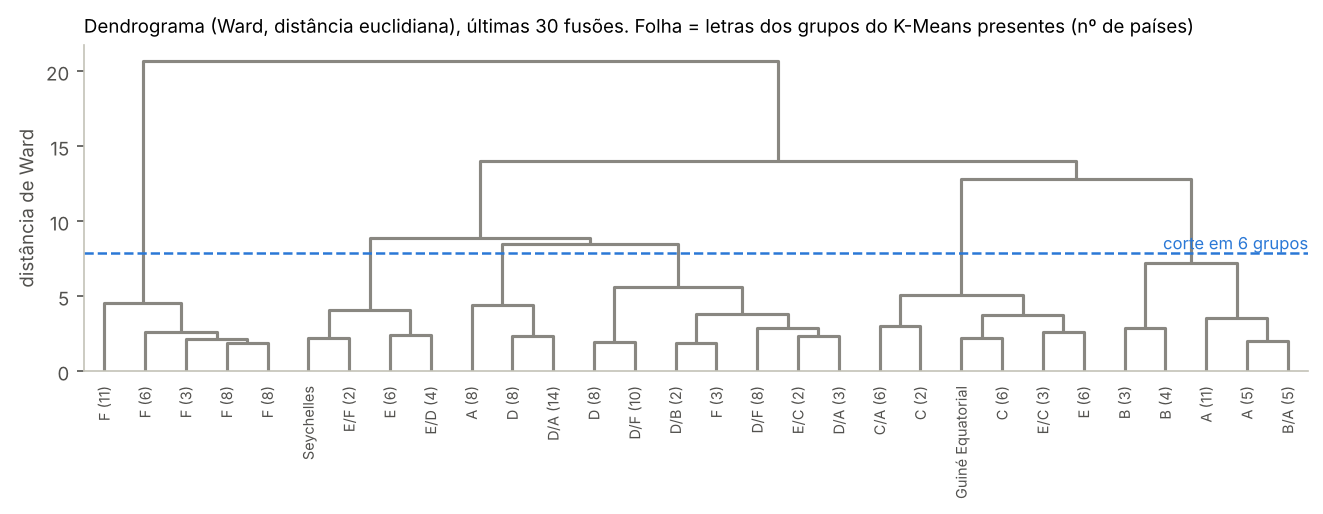

 k  corte_de  corte_ate  amplitude
 2     14.04      20.72       6.68
 3     12.80      14.04       1.24
 4      8.92      12.80       3.88
 5      8.51       8.92       0.41
 6      7.25       8.51       1.26
 7      5.64       7.25       1.61
 8      5.10       5.64       0.54
 9      4.53       5.10       0.57

Ward cortado em 2:
Ward                                                 1   2
K-Means                                                   
A. Alta necessidade, saúde subfinanciada             0  31
B. Alta necessidade, gasto em saúde alto             0  11
C. Alta necessidade, inflação alta                   0  16
D. Renda média, estável                              0  47
E. Renda média-alta, inflação alta, pouco gasto...   0  19
F. Desenvolvidos                                    36   7

Ward cortado em 3:
Ward                                                 1   2   3
K-Means                                                       
A. Alta necessidade, saúde subfinanciada       

In [14]:
dist = pdist(Xs, metric="euclidean")
ligacoes = {}
for metodo in ("ward", "complete", "average", "single"):
    Z_m = linkage(Xs, method=metodo)
    tamanhos = np.bincount(fcluster(Z_m, K_FINAL, criterion="maxclust"))[1:]
    ligacoes[metodo] = {"cofenetica": round(cophenet(Z_m, dist)[0], 3),
                        "tamanhos_com_6_grupos": sorted(tamanhos.tolist(), reverse=True)}
print(pd.DataFrame(ligacoes).T)

Z = linkage(Xs, method="ward")
rotulo_hc = pd.Series(fcluster(Z, K_FINAL, criterion="maxclust"), index=Xs.index)
print("Silhueta Ward k=6:", round(silhouette_score(Xs, rotulo_hc), 3))
print("ARI K-Means x Ward:", round(adjusted_rand_score(rotulo_km, rotulo_hc), 3))
cruzada = pd.crosstab(grupo, rotulo_hc, rownames=["K-Means"], colnames=["Ward"])
cruzada.to_csv("saidas/kmeans_vs_ward.csv")
print(cruzada)

altura_corte = (Z[-K_FINAL, 2] + Z[-K_FINAL + 1, 2]) / 2
# nomes em português só para os rótulos das figuras
NOMES_PT = {"Haiti": "Haiti", "Sierra Leone": "Serra Leoa", "Chad": "Chade",
            "Central African Republic": "R. Centro-Africana", "Nigeria": "Nigéria", "Yemen": "Iêmen",
            "Liberia": "Libéria", "Burundi": "Burundi", "Afghanistan": "Afeganistão", "India": "Índia",
            "Venezuela": "Venezuela", "Qatar": "Catar", "Equatorial Guinea": "Guiné Equatorial",
            "United States": "Estados Unidos", "Brazil": "Brasil", "Mongolia": "Mongólia",
            "Moldova": "Moldávia", "Seychelles": "Seychelles"}
_, nos = to_tree(Z, rd=True)


def rotulo_folha(i):
    """Cada folha do dendrograma truncado mostra as letras dos grupos do K-Means
    que estão dentro dela (a mais frequente primeiro) e o número de países."""
    membros = nos[i].pre_order()
    if len(membros) == 1:
        return NOMES_PT.get(grupo.index[membros[0]], grupo.index[membros[0]])
    letras = grupo.iloc[membros].str[0].value_counts()
    return f"{'/'.join(letras.index)} ({len(membros)})"


fig, ax = plt.subplots(figsize=(9, 3.5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_label_func=rotulo_folha, leaf_font_size=7,
           leaf_rotation=90, color_threshold=0, above_threshold_color=CINZA, ax=ax)
ax.axhline(altura_corte, color=AZUL, lw=1.2, ls="--")
ax.text(ax.get_xlim()[1], altura_corte, f"  corte em {K_FINAL} grupos", color=AZUL,
        va="bottom", ha="right", fontsize=8)
ax.set_ylabel("distância de Ward")
ax.set_title("Dendrograma (Ward, distância euclidiana), últimas 30 fusões. "
             "Folha = letras dos grupos do K-Means presentes (nº de países)", fontsize=9, loc="left")
fig.tight_layout()
fig.savefig("figuras/fig4_dendrograma.png", bbox_inches="tight")
plt.show()

# para obter k grupos o corte precisa ficar entre a fusão que leva de k+1 para k grupos
# e a que leva de k para k-1; quanto mais larga essa faixa, mais "natural" é o corte em k
alt = Z[::-1, 2]   # alt[0] = fusão de 2 para 1 grupo, alt[1] = de 3 para 2, ...
faixas = pd.DataFrame({"k": range(2, 10), "corte_de": alt[1:9], "corte_ate": alt[0:8]})
faixas["amplitude"] = faixas["corte_ate"] - faixas["corte_de"]
print(faixas.round(2).to_string(index=False))

# como os grupos do K-Means se encaixam nos primeiros cortes do dendrograma
for k in (2, 3, 4):
    print(f"\nWard cortado em {k}:")
    print(pd.crosstab(grupo, fcluster(Z, k, criterion="maxclust"), rownames=["K-Means"], colnames=["Ward"]))

### Leitura do dendrograma
- **Onde a árvore sugere cortar.** A faixa de corte mais larga é a de 2 grupos (6,68): a
  primeira divisão separa os desenvolvidos (36 do grupo F) de todo o resto. A segunda é a
  de 4 grupos (3,88). A faixa de 6 grupos é estreita (1,26), ou seja, a árvore não aponta
  6 como corte natural. Isso combina com a silhueta baixa: o número de grupos é uma
  decisão de utilidade, justificada na seção 6.
- **Primeiros cortes.** Com 3 grupos, o Ward separa um bloco de alta necessidade (19 de A,
  10 de B, 15 de C e 8 de E) de um bloco intermediário. Com 4, a inflação alta vira um
  grupo próprio (15 de C e 8 de E).
- **Onde os dois métodos concordam.** F fica quase inteiro num grupo Ward (36 de 43) e C
  também (15 de 16). B fica junto com a parte mais pobre de A (10 de 11).
- **Onde divergem.** (1) O Ward manda 11 países de A para o grupo intermediário, junto com
  o D; os países de A que a seção 9 marca como instáveis (Bolívia, Índia, Quirguistão,
  Turcomenistão, Vanuatu) estão todos nesse bloco. (2) O Ward põe junto com C os 8 países
  de E de renda média e inflação alta (Argélia, Azerbaijão, Gabão, Indonésia, Irã,
  Cazaquistão, Sri Lanka, Venezuela) e deixa os ricos do Golfo à parte; o K-Means separa
  esses 8 de C pela renda e pela mortalidade infantil mais baixas.

## 9. Robustez: métrica de distância e escolha dos indicadores
Refazemos o agrupamento com 6 grupos mudando uma decisão por vez e verificamos se os
países de alta necessidade (A, B e C) continuam separados dos demais. Em cada cenário, um
grupo conta como prioritário quando mais da metade dos seus membros está em A, B ou C.

- **Métrica e algoritmo**: Ward; K-Medoids com distância euclidiana e com Manhattan (o
  K-Means não aceita Manhattan, o K-Medoids sim); K-Means com distância de Mahalanobis.
- **Indicadores**: trocar cada um por uma variável redundante (PIB per capita no lugar da
  renda; pobreza extrema, cesta básica ou expectativa de vida no lugar da mortalidade
  infantil); retirar a inflação; retirar o gasto em saúde; trocar a inflação por exportações.

Mahalanobis e exportações são cenários de contraste, que as seções 2 e 5 já rejeitaram
por argumento. Por isso não entram na contagem de estabilidade de cada país, usada na
seção 11.

In [15]:
def kmedoids(matriz, k, metrica, inicios=50):
    """K-Medoids simples: alterna entre atribuir cada país ao medoide mais próximo e
    trocar o medoide pelo membro mais central do grupo. Várias partidas aleatórias."""
    D = cdist(matriz, matriz, metrica)
    rng_kmed = np.random.default_rng(SEMENTE)
    melhor = None
    for _ in range(inicios):
        med = rng_kmed.choice(len(matriz), k, replace=False)
        for _ in range(100):
            lab = D[:, med].argmin(axis=1)
            novo = np.array([np.flatnonzero(lab == j)[D[np.ix_(lab == j, lab == j)].sum(axis=1).argmin()]
                             for j in range(k)])
            if set(novo) == set(med):
                break
            med = novo
        lab = D[:, med].argmin(axis=1)
        custo = D[np.arange(len(matriz)), med[lab]].sum()
        if melhor is None or custo < melhor[0]:
            melhor = (custo, lab)
    return melhor[1]


def padroniza(colunas):
    return pd.DataFrame(StandardScaler().fit_transform(imputado_t[colunas]),
                        index=Xs.index, columns=colunas)


def km_com(colunas):
    return melhor_kmeans(K_FINAL, rodadas=20, matriz=padroniza(colunas)).labels_


def troca(velho, novo):
    return [novo if c == velho else c for c in INDICADORES]


def prioritarios_no_cenario(rotulos):
    """Países cujo grupo, no cenário, é formado majoritariamente por países de A, B ou C."""
    rotulos = pd.Series(np.asarray(rotulos), index=Xs.index)
    return rotulos.map(eh_prior.groupby(rotulos).mean() > 0.5)


# Mahalanobis = euclidiana depois de "branquear" os dados (Xs @ L tem covariância identidade)
L = np.linalg.cholesky(np.linalg.inv(np.cov(Xs.T)))
cenarios = {  # nome: (rótulos, entra na contagem de estabilidade?)
    "Ward (euclidiana)": (rotulo_hc, True),
    "K-Medoids euclidiana": (kmedoids(Xs.values, K_FINAL, "euclidean"), True),
    "K-Medoids Manhattan": (kmedoids(Xs.values, K_FINAL, "cityblock"), True),
    "renda -> PIB per capita": (km_com(troca("income", "gdpp")), True),
    "mort. infantil -> pobreza extrema": (km_com(troca("child_mort", "extrema_pobreza_pct")), True),
    "mort. infantil -> cesta básica": (km_com(troca("child_mort", "cesta_basica_salario_pct")), True),
    "mort. infantil -> expect. de vida": (km_com(troca("child_mort", "life_expec")), True),
    "sem inflação": (km_com(["child_mort", "income", "health"]), True),
    "sem gasto em saúde": (km_com(["child_mort", "income", "inflation"]), True),
    "K-Means Mahalanobis (contraste)": (melhor_kmeans(K_FINAL, 20, Xs.values @ L).labels_, False),
    "inflação -> exportações (contraste)": (km_com(troca("inflation", "exports")), False),
}

linhas, contagem = [], {}
for nome, (rot, conta) in cenarios.items():
    p = prioritarios_no_cenario(rot)
    if conta:
        contagem[nome] = p
    linhas.append({"cenario": nome, "ARI_com_final": round(adjusted_rand_score(rotulo_km, rot), 3),
                   "prioritarios_mantidos": f"{int((p & eh_prior).sum())}/{int(eh_prior.sum())}",
                   "entram": ", ".join(sorted(Xs.index[p & ~eh_prior])) or "-",
                   "saem": ", ".join(sorted(Xs.index[~p & eh_prior])) or "-"})
robustez = pd.DataFrame(linhas).set_index("cenario")
robustez.to_csv("saidas/robustez_cenarios.csv")
print(robustez[["ARI_com_final", "prioritarios_mantidos"]].to_string())
for nome, r in robustez.iterrows():
    print(f"\n{nome}\n  entram: {r['entram']}\n  saem:   {r['saem']}")

# em quantos dos 9 cenários válidos cada país ficou num grupo prioritário
contagem = pd.DataFrame(contagem)
n_cen = contagem.shape[1]
vezes_prior = contagem.sum(axis=1)
concorda = np.where(eh_prior, vezes_prior, n_cen - vezes_prior)  # cenários que concordam com o modelo final
print(f"\nPaíses que discordam do modelo final em 3 ou mais dos {n_cen} cenários:")
instaveis = pd.DataFrame({"grupo": grupo, "vezes_prioritario": vezes_prior})[concorda <= n_cen - 3]
print(instaveis.sort_values(["grupo", "vezes_prioritario"]).to_string())

                                     ARI_com_final prioritarios_mantidos
cenario                                                                 
Ward (euclidiana)                            0.511                 44/58
K-Medoids euclidiana                         0.839                 56/58
K-Medoids Manhattan                          0.570                 51/58
renda -> PIB per capita                      0.904                 57/58
mort. infantil -> pobreza extrema            0.737                 50/58
mort. infantil -> cesta básica               0.774                 56/58
mort. infantil -> expect. de vida            0.661                 55/58
sem inflação                                 0.500                 50/58
sem gasto em saúde                           0.587                 48/58
K-Means Mahalanobis (contraste)              0.434                 52/58
inflação -> exportações (contraste)          0.389                 40/58

Ward (euclidiana)
  entram: Algeria, Azerbaijan, G

### O que os cenários mostram
- **Trocar um indicador por outro redundante muda pouco.** Com PIB per capita no lugar da
  renda, 57 dos 58 prioritários continuam (ARI 0,90). Com cesta básica, expectativa de vida
  ou pobreza extrema no lugar da mortalidade infantil, ficam de 50 a 56. Isso confirma na
  prática que essas variáveis carregam a mesma informação e que escolher uma ou outra não
  muda a recomendação.
- **A métrica pesa pouco no núcleo.** O K-Medoids com distância euclidiana mantém 56 de 58;
  com Manhattan, 51 de 58. Os que saem com Manhattan são países de fronteira (Bolívia, Guiné
  Equatorial, Quirguistão, Moldávia, Ilhas Salomão, Turcomenistão, Vanuatu).
- **Os cenários de contraste confirmam as escolhas.** A Mahalanobis, ao tirar o peso extra
  do eixo de necessidade, puxa para a prioridade países de renda média (Argentina, Belarus,
  Rússia, Ucrânia...) e tira Nigéria e Angola, que têm mortalidade infantil acima de 100 por
  mil. Trocar inflação por exportações tira 18 prioritários e embaralha os grupos (ARI 0,39).
- **Retirar a inflação ou o gasto em saúde** tira de 8 a 10 países de fronteira, mas não traz
  ninguém de fora: os indicadores de estratégia separam perfis dentro da necessidade, sem
  mudar quem é necessitado.
- **Os mesmos países aparecem em quase todas as perturbações** (Bolívia, Turcomenistão,
  Vanuatu, Quirguistão, Guiné Equatorial, Iraque, Moldávia, Índia). A classificação final
  marca esses casos para revisão em vez de esconder a incerteza.

## 10. Mapa dos grupos (PCA só para visualização)

Variância explicada: [0.557 0.254]
Cargas:
              PC1   PC2
child_mort  0.63  0.24
income     -0.55 -0.51
inflation   0.41 -0.50
health     -0.36  0.65


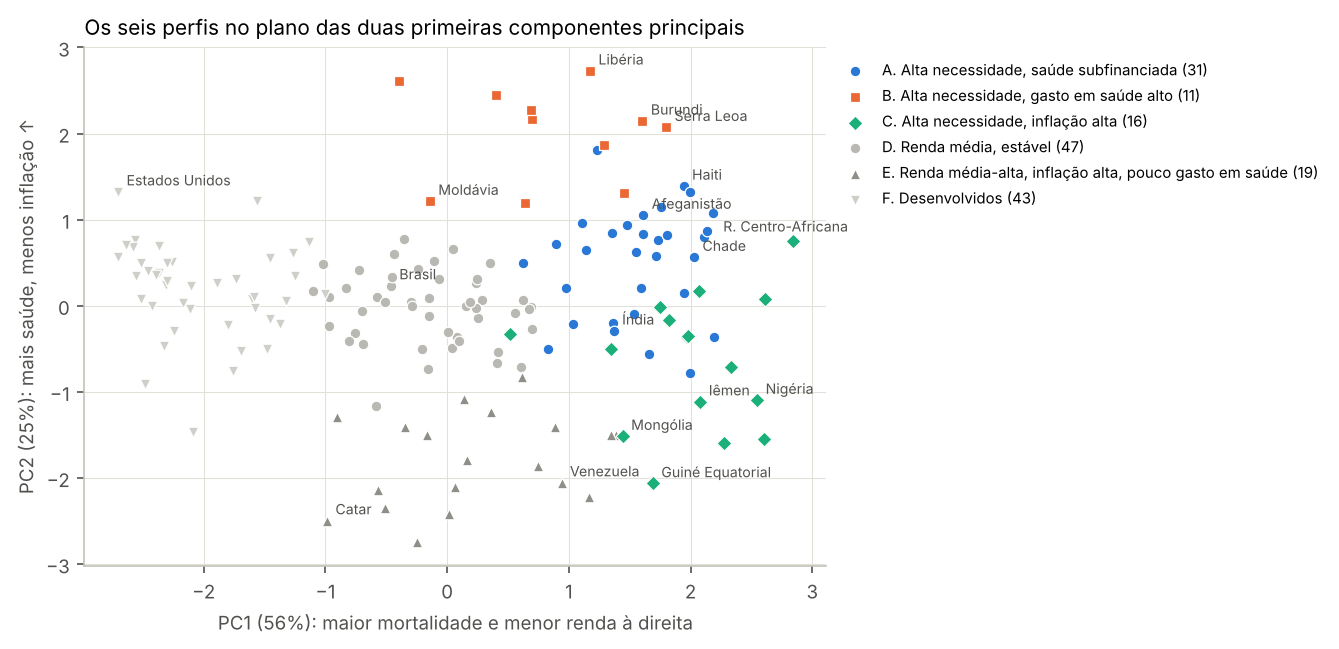

In [16]:
pca = PCA(n_components=2).fit(Xs)
pcs = pd.DataFrame(pca.transform(Xs), index=Xs.index, columns=["PC1", "PC2"])
print("Variância explicada:", pca.explained_variance_ratio_.round(3))
print("Cargas:\n", pd.DataFrame(pca.components_.T, index=INDICADORES, columns=["PC1", "PC2"]).round(2))

# estilo por letra do grupo: cor nos três de alta necessidade, cinza no resto
estilo_letra = {"A": (AZUL, "o"), "B": (LARANJA, "s"), "C": (VERDE_AGUA, "D"),
                "D": ("#b9b8b2", "o"), "E": ("#8f8e88", "^"), "F": ("#cfcec8", "v")}
estilo = {g: estilo_letra[g[0]] for g in grupo.unique()}
sinal = 1 if pca.components_[0, INDICADORES.index("child_mort")] > 0 else -1
fig, ax = plt.subplots(figsize=(9, 4.4))
for g in sorted(estilo):
    cor, mk = estilo[g]
    m = grupo == g
    ax.scatter(sinal * pcs.loc[m, "PC1"], pcs.loc[m, "PC2"], s=26, c=cor, marker=mk,
               edgecolors="white", linewidths=0.6, label=f"{g} ({m.sum()})", zorder=3 if g < "D" else 2)
destaques = ["Haiti", "Sierra Leone", "Chad", "Central African Republic", "Nigeria", "Yemen",
             "Liberia", "Burundi", "Afghanistan", "India", "Venezuela", "Qatar", "Equatorial Guinea",
             "United States", "Brazil", "Mongolia", "Moldova"]
for p in destaques:
    desloc = (5, -9) if p == "Central African Republic" else (4, 3)
    ax.annotate(NOMES_PT[p], (sinal * pcs.loc[p, "PC1"], pcs.loc[p, "PC2"]), fontsize=6.8,
                textcoords="offset points", xytext=desloc, color="#52514e")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%}): maior mortalidade e menor renda à direita")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%}): mais saúde, menos inflação ↑")
ax.set_title("Os seis perfis no plano das duas primeiras componentes principais", fontsize=10, loc="left")
ax.legend(fontsize=7.2, frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
ax.grid(color="#e1e0d9", lw=0.5)
fig.tight_layout()
fig.savefig("figuras/fig5_mapa_pca.png", bbox_inches="tight")
plt.show()

## 11. Resultado por país e classificação final
O grupo diz **que tipo de ajuda** cada país precisa; a classificação abaixo diz **quão
segura** é a indicação de prioridade:

- **Prioridade confirmada**: está em A, B ou C e o resultado se repete em pelo menos
  7 dos 9 cenários da seção 9.
- **Revisar caso a caso**: o resultado muda em 3 ou mais cenários (para dentro ou para
  fora da prioridade), ou o país está fora de A, B e C com mortalidade infantil acima de
  50 por mil, o dobro da meta da ONU para 2030 (ODS 3.2: no máximo 25 por mil).
- **Não prioritário**: o resto.

A coluna `imputado` mostra quais indicadores do país foram preenchidos na seção 4.

In [17]:
LIMITE_MORT = 50   # dobro da meta ODS 3.2 (25 mortes de menores de 5 anos por mil nascidos vivos)
estavel = pd.Series(concorda >= n_cen - 2, index=Xs.index)
alerta_mort = ~eh_prior & (completo["child_mort"] > LIMITE_MORT)
classificacao = pd.Series("Não prioritário", index=Xs.index)
classificacao[eh_prior & estavel] = "Prioridade confirmada"
classificacao[~estavel | alerta_mort] = "Revisar caso a caso"

resultado = completo[INDICADORES].round(2).copy()
resultado["imputado"] = faltavam.apply(lambda r: ", ".join(r.index[r]), axis=1)
resultado["grupo"] = grupo
resultado["silhueta"] = sil.round(3)
resultado["grupo_ward"] = rotulo_hc
resultado["cenarios_prioritario"] = vezes_prior.astype(int).astype(str) + f"/{n_cen}"
resultado["classificacao"] = classificacao
resultado = resultado.sort_values(["grupo", "child_mort"], ascending=[True, False])
resultado.to_csv("saidas/paises_por_grupo.csv")

print(pd.crosstab(resultado["grupo"], resultado["classificacao"], margins=True, margins_name="total"))
revisar = resultado[resultado["classificacao"] == "Revisar caso a caso"]
print("\nRevisar caso a caso:")
print(revisar[["grupo", "child_mort", "income", "inflation", "health", "cenarios_prioritario"]].to_string())

classificacao                                       Não prioritário  Prioridade confirmada  Revisar caso a caso  total
grupo                                                                                                                 
A. Alta necessidade, saúde subfinanciada                          0                     26                    5     31
B. Alta necessidade, gasto em saúde alto                          0                     10                    1     11
C. Alta necessidade, inflação alta                                0                     14                    2     16
D. Renda média, estável                                          44                      0                    3     47
E. Renda média-alta, inflação alta, pouco gasto...               16                      0                    3     19
F. Desenvolvidos                                                 43                      0                    0     43
total                                           

## 12. Recomendação por perfil
Cada grupo de alta necessidade pede uma estratégia diferente; a tabela junta o perfil,
quantos países estão confirmados e a linha de ação sugerida. Os países em "revisar caso a
caso" entram depois de uma análise individual com as variáveis suplementares.

In [18]:
ESTRATEGIA = {
    "A": "Financiar o sistema de saúde: atenção primária, vacinação e saúde materno-infantil. "
         "O gasto em saúde é baixo, então há espaço para o dinheiro novo virar resultado.",
    "B": "O país já gasta uma fatia grande do PIB em saúde, muitas vezes com apoio externo. "
         "Foco em eficiência e no que está fora da saúde (nutrição, água e saneamento, renda), "
         "coordenado com os doadores que já atuam.",
    "C": "Ajuda em bens e serviços (alimentos, medicamentos, insumos) em vez de dinheiro, "
         "contratos em moeda forte e revisão frequente de valores, porque a inflação corrói transferências.",
    "D": "Fora do fundo principal. Projetos focalizados só nos casos sinalizados para revisão.",
    "E": "Fora do fundo principal. Em geral têm renda para financiar a própria resposta; "
         "apoio técnico pontual nos casos sinalizados.",
    "F": "Não recebem ajuda; potenciais parceiros e doadores.",
}
rec = resultado.groupby("grupo").agg(
    n=("grupo", "size"),
    confirmados=("classificacao", lambda s: (s == "Prioridade confirmada").sum()),
    revisar=("classificacao", lambda s: (s == "Revisar caso a caso").sum()),
    mort_infantil=("child_mort", "median"), renda=("income", "median"),
    inflacao=("inflation", "median"), saude=("health", "median"))
rec["estrategia"] = [ESTRATEGIA[g[0]] for g in rec.index]
rec.round(1).to_csv("saidas/recomendacao_por_grupo.csv")
with pd.option_context("display.max_colwidth", 60):
    print(rec.drop(columns="estrategia").round(1).to_string())
for g, r in rec.iterrows():
    print(f"\n{g}: {r['estrategia']}")

                                                           n  confirmados  revisar  mort_infantil    renda  inflacao  saude
grupo                                                                                                                      
A. Alta necessidade, saúde subfinanciada                  31           26        5           88.2   2090.0       6.4    5.1
B. Alta necessidade, gasto em saúde alto                  11           10        1           81.0   1540.0       5.5   11.3
C. Alta necessidade, inflação alta                        16           14        2           75.7   3805.0      20.2    5.2
D. Renda média, estável                                   47            0        3           18.9   9930.0       4.2    6.2
E. Renda média-alta, inflação alta, pouco gasto em saúde  19            0        3           14.5  20100.0      15.6    4.2
F. Desenvolvidos                                          43            0        0            4.5  32500.0       1.2    9.4

A. Alta

## Resumo das decisões (base para o relatório)

| Pergunta | Decisão | Embasamento |
|---|---|---|
| Quais indicadores? | Mortalidade infantil, renda, inflação e gasto em saúde | Dois de necessidade e dois que orientam a estratégia. A mortalidade infantil representa um bloco de 11 variáveis de desenvolvimento (\|rho\| de 0,87 a 0,95 com ela); trocá-la (ou trocar a renda) por uma variável redundante mantém de 50 a 57 dos 58 prioritários (seções 2 e 9). |
| Faltantes? | Valores impossíveis e o código 99999 viram faltantes (20 valores). KNN (k = 5) na mortalidade, na inflação e na saúde; MICE na renda | Validação em 100 rodadas escondendo valores conhecidos: o KNN erra menos em três indicadores e o MICE erra cerca de 40% menos na renda. Com KNN, a renda de Bangladesh ficaria 8,9 vezes o PIB per capita (máximo observado: 4,1). Os grupos são os mesmos com qualquer dos dois (ARI = 1). |
| Outliers? | Winsorização nas cercas de Tukey, depois do log, sem excluir países | Os outliers são países reais (Haiti na mortalidade, Catar na renda, Nigéria na inflação); excluí-los tiraria justamente casos extremos. A winsorização só afeta a matriz de agrupamento. |
| Assimetria? | Log na mortalidade infantil e na renda (assimetria de 1,45 e 2,21 para −0,02 e −0,25). Inflação sem log, porque tem valores negativos | Yeo-Johnson foi testada na inflação e descartada: transforma deflação leve (Irlanda, Seychelles) em outlier. |
| Escalonamento? | z-score | Sem ele, a renda responde por praticamente 100% da variância e decide sozinha a distância. |
| Distância? | Euclidiana | Coerente com o K-Means e o Ward; extremos já tratados; o peso extra do eixo de necessidade é desejado. Mahalanobis e Manhattan testadas na seção 9. |
| Número de grupos e método | K-Means com k = 6; Ward como segunda opinião | Silhueta empatada entre k = 3 e k = 6 (teste em subamostras); só k = 6 separa países pobres com inflação alta dos ricos do Golfo. Bootstrap com ARI médio de 0,75. Ward escolhido por usar o mesmo critério do K-Means. |
| Recomendação | 50 países com prioridade confirmada (26 em A, 10 em B, 14 em C), 14 para revisar caso a caso e uma estratégia por grupo | Seções 11 e 12. |